# Reading an fMRI dataset with PyBIDS
## A beginner's hands-on notebook

Find subjects, sessions, anatomical images, tasks, and runs, then read image values and metadata.

**Start here:** run cells from top to bottom. The default demo creates tiny synthetic images, so no participant data or downloads are needed. The numbers are teaching examples, not brain measurements. After exploring, change the configuration cell to use your dataset.

**Tools:** PyBIDS locates files; NiBabel reads NIfTI images; pandas displays tables. No preprocessing is performed.

This notebook includes worked examples, five short self-checks, and automated tests. Answers are folded beneath each quiz. Documentation links are collected at the end.

## 1. Installation — run once per Python environment
`%pip` installs into the notebook kernel's environment. Installation needs internet access. If Jupyter requests a kernel restart, restart and continue from the configuration cell. The remaining cells work offline on the demo.

In [2]:

import os, socket, sys
print(socket.gethostname())
print(sys.executable)
print({k: v for k, v in os.environ.items() if 'proxy' in k.lower()})

login01
/lustre/disk/home/users/mfaizan/miniconda3/envs/moco/bin/python
{'NO_PROXY': 'localhost,127.0.0.1', 'HTTPS_PROXY': 'http://localhost:8899', 'HTTP_PROXY': 'http://localhost:8899'}


In [1]:
%pip install -q pybids nibabel numpy pandas matplotlib

^C
ERROR: Operation cancelled by user
Note: you may need to restart the kernel to use updated packages.


## 2. Configuration — make your changes here
Labels are strings **without** prefixes: use `"001"`, not `"sub-001"`. Task labels must match your filenames exactly.

For your data, set `USE_DEMO = False` and edit `BIDS_ROOT`. This is the folder containing `dataset_description.json`, not one subject's folder. Change the selection values to labels that exist in your dataset. Real-data queries only read files.

`RUN` identifies a repeated acquisition; it is not necessarily the chronological scan number of the session. The same run number can occur for multiple tasks and sessions.

In [2]:
from pathlib import Path

USE_DEMO = True
BIDS_ROOT = Path("/path/to/your/bids_dataset")
DEMO_PARENT = Path.cwd() / "pybids_learning_demo"

SUBJECT = "001"
SUBJECTS = ["001", "002"]
SESSION = "01"
TASK = "video"
TASKS = ["video", "rest"]
RUN = 2
RUNS = [1, 2]

NIFTI_EXTENSIONS = [".nii", ".nii.gz"]
TIME_START = 0                  # Inclusive time-point index
TIME_STOP = 3                   # Exclusive time-point index
RANDOM_SEED = 42
DEMO_SHAPE = (8, 8, 4, 6)       # x, y, z, time — deliberately tiny
DEMO_TR_SECONDS = 0.61
DEMO_TE_SECONDS = 0.032
DEMO_BIDS_VERSION = "1.10.0"    # Declared format version, not a claim of latest version
MAX_TABLE_ROWS = 20
LOAD_FULL_RUN = False           # Leave False to load only a small time block

## 3. Imports and package versions
Printing versions makes your results easier to reproduce.

In [3]:
import json
import tempfile
from importlib.metadata import version

import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from IPython.display import display
from bids import BIDSLayout

for package in ["pybids", "nibabel", "numpy", "pandas", "matplotlib"]:
    print(f"{package}: {version(package)}")

pybids: 0.22.0
nibabel: 5.4.2
numpy: 2.3.5
pandas: 2.2.3
matplotlib: 3.10.8


## 4. Create the small practice dataset
You can skim this setup cell on your first pass. It writes only to a **new temporary demo folder** beneath `DEMO_PARENT`. It never deletes an existing folder or writes to `BIDS_ROOT`.

The demo deliberately has unequal coverage: not every subject has every session or task. There are **11 BOLD runs** in total:

| Subject | Session | Pictures runs | Video runs | Rest runs |
|---|---|---|---|---|
| 001 | 01 | 1 | 1, 2 | 1 |
| 001 | 02 | — | 1 | 1 |
| 002 | 01 | 1 | 1 | 1 |
| 003 | 01 | — | 1, 2 | — |

Each listed session also has one T1w and one T2w image. Task scans have events files; rest scans do not. The synthetic files teach querying; they are not a scientifically realistic acquisition or a claim of full BIDS-validator certification.

In [4]:
def create_demo_dataset(parent):
    """Create a fresh teaching dataset and return its root and expected run list."""
    parent.mkdir(parents=True, exist_ok=True)
    root = Path(tempfile.mkdtemp(prefix="dataset_", dir=parent))
    rng = np.random.default_rng(RANDOM_SEED)
    rows = [
        ("001", "01", "pictures", 1),
        ("001", "01", "video", 1),
        ("001", "01", "video", 2),
        ("001", "01", "rest", 1),
        ("001", "02", "video", 1),
        ("001", "02", "rest", 1),
        ("002", "01", "pictures", 1),
        ("002", "01", "video", 1),
        ("002", "01", "rest", 1),
        ("003", "01", "video", 1),
        ("003", "01", "video", 2),
    ]
    description = {
        "Name": "Synthetic PyBIDS learning dataset",
        "BIDSVersion": DEMO_BIDS_VERSION,
        "DatasetType": "raw",
    }
    (root / "dataset_description.json").write_text(json.dumps(description, indent=2))
    (root / "README").write_text("Synthetic teaching images. Not participant data.\n")
    pd.DataFrame({"participant_id": ["sub-001", "sub-002", "sub-003"]}).to_csv(
        root / "participants.tsv", sep="\t", index=False
    )

    for subject, session in sorted({(s, se) for s, se, _, _ in rows}):
        anat_dir = root / f"sub-{subject}" / f"ses-{session}" / "anat"
        anat_dir.mkdir(parents=True)
        for contrast in ["T1w", "T2w"]:
            image = nib.Nifti1Image(
                rng.normal(100, 5, DEMO_SHAPE[:3]).astype(np.float32), np.eye(4)
            )
            nib.save(image, anat_dir / f"sub-{subject}_ses-{session}_{contrast}.nii.gz")

    for subject, session, task, run in rows:
        func_dir = root / f"sub-{subject}" / f"ses-{session}" / "func"
        func_dir.mkdir(parents=True, exist_ok=True)
        stem = f"sub-{subject}_ses-{session}_task-{task}_run-{run:02d}"
        values = rng.normal(100, 2, DEMO_SHAPE).astype(np.float32)
        # Give each time point an offset so slicing can be checked meaningfully.
        values += np.arange(DEMO_SHAPE[-1], dtype=np.float32)[None, None, None, :]
        image = nib.Nifti1Image(values, np.eye(4))
        image.header.set_xyzt_units("mm", "sec")
        image.header.set_zooms((3, 3, 3.3, DEMO_TR_SECONDS))
        nib.save(image, func_dir / f"{stem}_bold.nii.gz")
        metadata = {"TaskName": task, "RepetitionTime": DEMO_TR_SECONDS,
                    "EchoTime": DEMO_TE_SECONDS, "MultibandAccelerationFactor": 4}
        (func_dir / f"{stem}_bold.json").write_text(json.dumps(metadata, indent=2))
        if task != "rest":
            pd.DataFrame({"onset": [0.0, 1.5], "duration": [1.0, 1.0],
                          "trial_type": [task, task]}).to_csv(
                func_dir / f"{stem}_events.tsv", sep="\t", index=False
            )
    return root, rows

if USE_DEMO:
    active_root, demo_manifest = create_demo_dataset(DEMO_PARENT)
else:
    active_root = BIDS_ROOT.expanduser().resolve()
    if not (active_root / "dataset_description.json").is_file():
        raise FileNotFoundError("Check BIDS_ROOT: dataset_description.json was not found.")

print("Dataset:", active_root)

Dataset: /workspace/scratch/8e6316e3a44d/pybids_learning_demo/dataset_q10svoy4


## 5. Index the dataset and discover its labels
Indexing finds filenames and metadata; it does **not** load all image arrays. We keep derivatives excluded here. PyBIDS filename validation is not a replacement for running the full BIDS Validator.

The first lists below describe the whole dataset. Filtered discovery then tells you what exists for one subject/session. A session label appearing globally does not mean every subject has that session.

In [5]:
layout = BIDSLayout(active_root, validate=True, derivatives=False)

print("All subjects:", layout.get_subjects())
print("All sessions:", layout.get_sessions())
print("All tasks:", layout.get_tasks())
print("Sessions for selected subject:", layout.get_sessions(subject=SUBJECT))
print("Tasks for selected subject/session:",
      layout.get_tasks(subject=SUBJECT, session=SESSION, datatype="func", suffix="bold"))
print("Runs for selected subject/session/task:",
      layout.get_runs(subject=SUBJECT, session=SESSION, task=TASK, suffix="bold"))

All subjects: ['001', '002', '003']
All sessions: ['01', '02']
All tasks: ['pictures', 'rest', 'video']
Sessions for selected subject: ['01', '02']
Tasks for selected subject/session: ['pictures', 'rest', 'video']
Runs for selected subject/session/task: [01, 02]


**Self-check 1:** If `get_sessions()` returns `['01', '02']`, does that prove subject 003 has session 02? Explain how you would check.

<details><summary>Show answer</summary>
No. The unfiltered result covers the dataset. Use <code>layout.get_sessions(subject="003")</code>; in the demo this returns only <code>['01']</code>.
</details>

## 6. Your first query: every BOLD image
`layout.get()` returns BIDS file objects by default. `return_type="filename"` returns paths instead. Specify the image extension so that `_bold.json` files are not included.

In [6]:
all_bold = layout.get(
    datatype="func",
    suffix="bold",
    extension=NIFTI_EXTENSIONS,
    return_type="filename",
)
print("Number of BOLD images:", len(all_bold))
for path in all_bold[:MAX_TABLE_ROWS]:
    print(Path(path).relative_to(active_root))

Number of BOLD images: 11
sub-001/ses-01/func/sub-001_ses-01_task-pictures_run-01_bold.nii.gz
sub-001/ses-01/func/sub-001_ses-01_task-rest_run-01_bold.nii.gz
sub-001/ses-01/func/sub-001_ses-01_task-video_run-01_bold.nii.gz
sub-001/ses-01/func/sub-001_ses-01_task-video_run-02_bold.nii.gz
sub-001/ses-02/func/sub-001_ses-02_task-rest_run-01_bold.nii.gz
sub-001/ses-02/func/sub-001_ses-02_task-video_run-01_bold.nii.gz
sub-002/ses-01/func/sub-002_ses-01_task-pictures_run-01_bold.nii.gz
sub-002/ses-01/func/sub-002_ses-01_task-rest_run-01_bold.nii.gz
sub-002/ses-01/func/sub-002_ses-01_task-video_run-01_bold.nii.gz
sub-003/ses-01/func/sub-003_ses-01_task-video_run-01_bold.nii.gz
sub-003/ses-01/func/sub-003_ses-01_task-video_run-02_bold.nii.gz


## 7. Small reusable helpers
The first helper fixes the repeated BOLD/image filters; you supply the changing selections. `**filters` means “pass named filters such as subject or task through to PyBIDS.”

The second helper displays a readable inventory. The third refuses to silently choose one image when a query returns zero or several matches.

In [7]:
def get_bold_files(layout, **filters):
    """Return sorted BOLD image paths matching the supplied entity filters."""
    return sorted(layout.get(
        datatype="func", suffix="bold", extension=NIFTI_EXTENSIONS,
        return_type="filename", **filters
    ))

def files_table(layout, paths):
    """Describe matched files without loading image values."""
    rows = []
    for path in paths:
        entities = layout.parse_file_entities(path)
        rows.append({
            "subject": entities.get("subject"),
            "session": entities.get("session"),
            "task": entities.get("task"),
            "run": entities.get("run"),
            "suffix": entities.get("suffix"),
            "filename": Path(path).name,
        })
    return pd.DataFrame(rows, columns=["subject", "session", "task", "run", "suffix", "filename"])

def require_one(paths):
    """Return the only match, or explain why selection needs attention."""
    if len(paths) != 1:
        raise ValueError(
            f"Expected exactly one image, found {len(paths)}. "
            "Inspect matches and check subject/session/task/run; "
            "multi-echo or multiple acquisitions may need additional filters."
        )
    return paths[0]

display(files_table(layout, all_bold).head(MAX_TABLE_ROWS))

,subject,session,task,run,suffix,filename
0,001,01,pictures,1,bold,sub-001_ses-01_task-pictures_run-01_bold.nii.gz
1,001,01,rest,1,bold,sub-001_ses-01_task-rest_run-01_bold.nii.gz
2,001,01,video,1,bold,sub-001_ses-01_task-video_run-01_bold.nii.gz
3,001,01,video,2,bold,sub-001_ses-01_task-video_run-02_bold.nii.gz
4,001,02,rest,1,bold,sub-001_ses-02_task-rest_run-01_bold.nii.gz
5,001,02,video,1,bold,sub-001_ses-02_task-video_run-01_bold.nii.gz
6,002,01,pictures,1,bold,sub-002_ses-01_task-pictures_run-01_bold.nii.gz
7,002,01,rest,1,bold,sub-002_ses-01_task-rest_run-01_bold.nii.gz
8,002,01,video,1,bold,sub-002_ses-01_task-video_run-01_bold.nii.gz
9,003,01,video,1,bold,sub-003_ses-01_task-video_run-01_bold.nii.gz


## 8. Retrieve one subject or a collection of subjects
A single label selects one subject. A list selects **either** subject. Without session/task/run filters, every matching session, task, and run is included.

In [8]:
one_subject = get_bold_files(layout, subject=SUBJECT)
several_subjects = get_bold_files(layout, subject=SUBJECTS)

print("One subject:", len(one_subject), "images")
display(files_table(layout, one_subject).head(MAX_TABLE_ROWS))
print("Selected subjects:", len(several_subjects), "images")
display(files_table(layout, several_subjects).head(MAX_TABLE_ROWS))

One subject: 6 images
Selected subjects: 9 images


,subject,session,task,run,suffix,filename
0,001,01,pictures,1,bold,sub-001_ses-01_task-pictures_run-01_bold.nii.gz
1,001,01,rest,1,bold,sub-001_ses-01_task-rest_run-01_bold.nii.gz
2,001,01,video,1,bold,sub-001_ses-01_task-video_run-01_bold.nii.gz
3,001,01,video,2,bold,sub-001_ses-01_task-video_run-02_bold.nii.gz
4,001,02,rest,1,bold,sub-001_ses-02_task-rest_run-01_bold.nii.gz
5,001,02,video,1,bold,sub-001_ses-02_task-video_run-01_bold.nii.gz


,subject,session,task,run,suffix,filename
0,001,01,pictures,1,bold,sub-001_ses-01_task-pictures_run-01_bold.nii.gz
1,001,01,rest,1,bold,sub-001_ses-01_task-rest_run-01_bold.nii.gz
2,001,01,video,1,bold,sub-001_ses-01_task-video_run-01_bold.nii.gz
3,001,01,video,2,bold,sub-001_ses-01_task-video_run-02_bold.nii.gz
4,001,02,rest,1,bold,sub-001_ses-02_task-rest_run-01_bold.nii.gz
5,001,02,video,1,bold,sub-001_ses-02_task-video_run-01_bold.nii.gz
6,002,01,pictures,1,bold,sub-002_ses-01_task-pictures_run-01_bold.nii.gz
7,002,01,rest,1,bold,sub-002_ses-01_task-rest_run-01_bold.nii.gz
8,002,01,video,1,bold,sub-002_ses-01_task-video_run-01_bold.nii.gz


## 9. Retrieve one task or a collection of tasks
`task=TASK` selects one task across all subjects and sessions. `task=TASKS` selects **any** task in that list.

Within one filter, list values mean **OR**. Between different filters, conditions mean **AND**. These queries return files that exist; they do not require each subject to have every selected task.

In [9]:
one_task = get_bold_files(layout, task=TASK)
task_collection = get_bold_files(layout, task=TASKS)
combined = get_bold_files(layout, subject=SUBJECTS, task=TASKS, session=SESSION)

print("One task:", len(one_task))
print("Collection of tasks:", len(task_collection))
print("Selected subjects AND selected session AND either selected task:")
display(files_table(layout, combined).head(MAX_TABLE_ROWS))

One task: 6
Collection of tasks: 9
Selected subjects AND selected session AND either selected task:


,subject,session,task,run,suffix,filename
0,001,01,rest,1,bold,sub-001_ses-01_task-rest_run-01_bold.nii.gz
1,001,01,video,1,bold,sub-001_ses-01_task-video_run-01_bold.nii.gz
2,001,01,video,2,bold,sub-001_ses-01_task-video_run-02_bold.nii.gz
3,002,01,rest,1,bold,sub-002_ses-01_task-rest_run-01_bold.nii.gz
4,002,01,video,1,bold,sub-002_ses-01_task-video_run-01_bold.nii.gz


**Self-check 2:** What does `subject=['001', '002'], task=['video', 'rest']` select?

Write your answer before expanding below.

<details><summary>Show answer</summary>
Files from subject 001 OR 002, whose task is video OR rest. Both the subject condition AND the task condition must hold. With no session filter, all matching sessions are eligible. It does not require subjects to have both tasks.
</details>

## 10. Retrieve one session and particular runs
First narrow down to a subject/session/task, then choose one run or a list of run numbers. A run filter alone applies across all tasks and sessions.

In [10]:
one_session = get_bold_files(layout, subject=SUBJECT, session=SESSION)
exact_run = get_bold_files(
    layout, subject=SUBJECT, session=SESSION, task=TASK, run=RUN
)
selected_runs = get_bold_files(
    layout, subject=SUBJECT, session=SESSION, task=TASK, run=RUNS
)

print("All BOLD images in the selected session:")
display(files_table(layout, one_session))
print("One particular task/run:")
display(files_table(layout, exact_run))
print("Collection of run numbers:")
display(files_table(layout, selected_runs))

All BOLD images in the selected session:
One particular task/run:
Collection of run numbers:


,subject,session,task,run,suffix,filename
0,001,01,pictures,1,bold,sub-001_ses-01_task-pictures_run-01_bold.nii.gz
1,001,01,rest,1,bold,sub-001_ses-01_task-rest_run-01_bold.nii.gz
2,001,01,video,1,bold,sub-001_ses-01_task-video_run-01_bold.nii.gz
3,001,01,video,2,bold,sub-001_ses-01_task-video_run-02_bold.nii.gz


,subject,session,task,run,suffix,filename
0,001,01,video,2,bold,sub-001_ses-01_task-video_run-02_bold.nii.gz


,subject,session,task,run,suffix,filename
0,001,01,video,1,bold,sub-001_ses-01_task-video_run-01_bold.nii.gz
1,001,01,video,2,bold,sub-001_ses-01_task-video_run-02_bold.nii.gz


**Self-check 3:** In the demo, how many images match `task='video', run=2` with no subject or session filter? Which ones?

<details><summary>Show answer</summary>
Two images: subject 001/session 01/video/run 02 and subject 003/session 01/video/run 02. Run 02 is not globally unique.
</details>

## 11. A task collection is different from complete task coverage
Suppose you need subjects who have **all** selected tasks in the chosen session. First query the task collection, then explicitly check coverage. Run counts can still differ.

In [11]:
coverage_files = get_bold_files(layout, session=SESSION, task=TASKS)
coverage = files_table(layout, coverage_files)
required_tasks = set(TASKS)

complete_subjects = [
    subject
    for subject, group in coverage.groupby("subject")
    if required_tasks.issubset(set(group["task"]))
]
print("Subjects with every selected task in this session:", complete_subjects)

# Avoid querying with an empty subject list: return an empty result explicitly.
complete_files = (
    get_bold_files(layout, subject=complete_subjects, session=SESSION, task=TASKS)
    if complete_subjects else []
)
display(files_table(layout, complete_files))

Subjects with every selected task in this session: ['001', '002']


,subject,session,task,run,suffix,filename
0,001,01,rest,1,bold,sub-001_ses-01_task-rest_run-01_bold.nii.gz
1,001,01,video,1,bold,sub-001_ses-01_task-video_run-01_bold.nii.gz
2,001,01,video,2,bold,sub-001_ses-01_task-video_run-02_bold.nii.gz
3,002,01,rest,1,bold,sub-002_ses-01_task-rest_run-01_bold.nii.gz
4,002,01,video,1,bold,sub-002_ses-01_task-video_run-01_bold.nii.gz


## 12. Retrieve anatomical images
Anatomical and functional images share subject/session labels, but use different datatype and suffix filters. Do not pass task filters when selecting these anatomical scans.

In [12]:
anatomical_files = layout.get(
    subject=SUBJECT, session=SESSION, datatype="anat",
    suffix=["T1w", "T2w"], extension=NIFTI_EXTENSIONS,
    return_type="filename",
)
display(files_table(layout, anatomical_files))

,subject,session,task,run,suffix,filename
0,001,01,None,None,T1w,sub-001_ses-01_T1w.nii.gz
1,001,01,None,None,T2w,sub-001_ses-01_T2w.nii.gz


## 13. Inspect metadata, then read part of a run
If the selected run is missing, the notebook reports that and keeps going. If several images match (for example, multi-echo data), refine the query instead of picking the first result blindly.

`nib.load()` opens an image proxy. Its shape/header can be inspected without loading the full array. Slicing `dataobj` requests only a chosen block into the resulting array; compressed files may still require substantial decompression. Time indices below are **volumes within one run**, not run numbers.

In [13]:
fmri_path = None
img = None
block = None
metadata = {}

if len(exact_run) == 1:
    fmri_path = require_one(exact_run)
    metadata = layout.get_metadata(fmri_path)
    print("Metadata:")
    display(metadata)

    img = nib.load(fmri_path)
    print("Shape (x, y, z, time):", img.shape)
    if len(img.shape) != 4:
        raise ValueError("This example expects a 4D BOLD image.")
    if not 0 <= TIME_START < TIME_STOP <= img.shape[3]:
        raise ValueError("Choose TIME_START/TIME_STOP within the available time points.")

    block = np.asarray(img.dataobj[..., TIME_START:TIME_STOP], dtype=np.float32)
    print("Selected block:", block.shape)
    print("TR in seconds:", metadata.get("RepetitionTime", "not available"))

    if LOAD_FULL_RUN:
        full_data = img.get_fdata(dtype=np.float32)
        print("Full run loaded:", full_data.shape)
else:
    print(f"Found {len(exact_run)} images. Edit the configuration or add query filters.")

Metadata:
Shape (x, y, z, time): (8, 8, 4, 6)
Selected block: (8, 8, 4, 3)
TR in seconds: 0.61


{'EchoTime': 0.032,
 'MultibandAccelerationFactor': 4,
 'RepetitionTime': 0.61,
 'TaskName': 'video'}

**Self-check 4:** What is the difference between `run=2` and `img.dataobj[..., 0:3]`?

<details><summary>Show answer</summary>
The run filter selects acquisition files labelled run 02. The array slice selects time-point indices 0, 1, and 2 within an already selected acquisition. Python excludes the stop index.
</details>

## 14. Look at one slice and a simple time trace
The left panel displays the middle z slice of the first selected volume. The right panel shows the spatial mean of the selected block. On real data, this unmasked mean includes background; it is a loading demonstration, not a brain-specific QC measure. The display uses array coordinates, not an anatomical orientation convention.

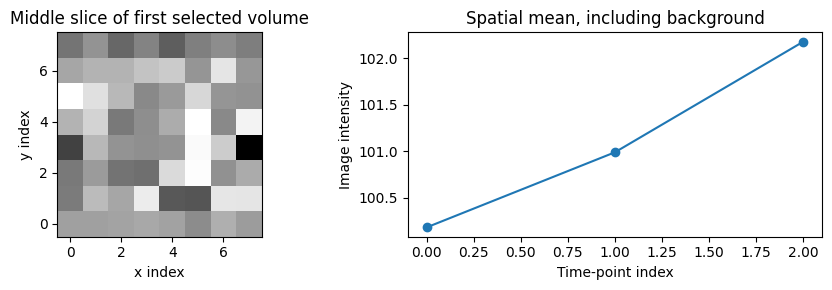

In [14]:
if block is not None:
    middle_z = block.shape[2] // 2
    spatial_mean = block.mean(axis=(0, 1, 2))
    time_indices = np.arange(TIME_START, TIME_STOP)

    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].imshow(block[:, :, middle_z, 0].T, cmap="gray", origin="lower")
    axes[0].set_title("Middle slice of first selected volume")
    axes[0].set_xlabel("x index")
    axes[0].set_ylabel("y index")
    axes[1].plot(time_indices, spatial_mean, marker="o")
    axes[1].set_title("Spatial mean, including background")
    axes[1].set_xlabel("Time-point index")
    axes[1].set_ylabel("Image intensity")
    fig.tight_layout()
    plt.show()
else:
    print("Select exactly one valid run above to display its image.")

## 15. Read the matching task events
`get_nearest()` can find a corresponding events file, including one stored higher in the hierarchy under BIDS inheritance. Strict matching compares the entities shared by the image and events file. We ignore suffix and extension in that comparison because BOLD images and events tables have different file types. This also allows a more general events file to be inherited. An absent events file is expected for many rest scans; task scans need their actual experimental timings.

`onset` and `duration` are seconds; `trial_type` describes the event category. Events are not individual fMRI volumes.

In [15]:
events = None
if fmri_path is not None:
    events_path = layout.get_nearest(
        fmri_path, suffix="events", extension=".tsv",
        strict=True, ignore_strict_entities=["suffix", "extension"]
    )
    if events_path is not None:
        events = pd.read_csv(events_path, sep="\t")
        display(events.head(MAX_TABLE_ROWS))
    else:
        print("No matching events.tsv found. Check whether this is a rest scan.")
else:
    print("Select one image first.")

,onset,duration,trial_type
0,0.0,1.0,video
1,1.5,1.0,video


## 16. Loop through matching runs without loading every array
This is a common starting point for your own analysis: select files, inspect one at a time, and collect results in a table. Here we read only image headers and JSON metadata.

In [16]:
summary_rows = []
for path in get_bold_files(layout, subject=SUBJECTS, task=TASKS):
    entities = layout.parse_file_entities(path)
    image = nib.load(path)
    scan_metadata = layout.get_metadata(path)
    summary_rows.append({
        "subject": entities.get("subject"),
        "session": entities.get("session"),
        "task": entities.get("task"),
        "run": entities.get("run"),
        "shape": image.shape,
        "n_volumes": image.shape[3] if len(image.shape) == 4 else None,
        "TR_seconds": scan_metadata.get("RepetitionTime"),
    })
run_summary = pd.DataFrame(summary_rows)
display(run_summary.head(MAX_TABLE_ROWS))

,subject,session,task,run,shape,n_volumes,TR_seconds
0,001,01,rest,1,"(8, 8, 4, 6)",6,0.61
1,001,01,video,1,"(8, 8, 4, 6)",6,0.61
2,001,01,video,2,"(8, 8, 4, 6)",6,0.61
3,001,02,rest,1,"(8, 8, 4, 6)",6,0.61
4,001,02,video,1,"(8, 8, 4, 6)",6,0.61
5,002,01,rest,1,"(8, 8, 4, 6)",6,0.61
6,002,01,video,1,"(8, 8, 4, 6)",6,0.61


## 17. Empty results and missing run labels
An empty list is a normal query result: the selected acquisition may not exist. Check discovered labels before changing validation settings.

A valid single acquisition can omit `run-` in its filename. Such a file has no explicit run entity; a query for `run=1` will not automatically treat that missing label as run 01. Leave the run filter out when appropriate and inspect the matches.

In [17]:
# Derive a subject label that cannot collide with the indexed labels.
absent_subject = "NoSuchSubject"
while absent_subject in layout.get_subjects():
    absent_subject += "X"

missing_files = get_bold_files(layout, subject=absent_subject)
print("Missing subject query:", missing_files)
print("No run restriction:", len(get_bold_files(
    layout, subject=SUBJECT, session=SESSION, task=TASK
)))

Missing subject query: []
No run restriction: 2


**Self-check 5 — write a query:** Select video and rest images for subjects 001 and 002, only in session 01 and only run 01. Predict the demo count.

<details><summary>Show answer</summary>
<pre>get_bold_files(layout, subject=["001", "002"], session="01",
               task=["video", "rest"], run=1)</pre>
The demo returns four images: one video and one rest run from each selected subject.
</details>

## 18. Automated checks with known answers
These checks verify query counts, OR/AND filtering, missing matches, image slicing, metadata, event matching, and rejection of ambiguous selections. Fixed expected counts apply **only to the unchanged demo**. Your real dataset is not required to match these counts.

The checks operate on returned files and image contents rather than merely repeating the helper definitions.

In [18]:
def run_demo_checks(layout):
    passed = 0

    def check(condition, label):
        nonlocal passed
        assert condition, f"FAILED: {label}"
        passed += 1
        print(f"PASS {passed:02d}: {label}")

    check(set(layout.get_subjects()) == {"001", "002", "003"}, "three subjects")
    check(layout.get_sessions(subject="003") == ["01"], "unequal session coverage")
    check(len(get_bold_files(layout)) == 11, "11 BOLD images, excluding JSON files")
    check(len(get_bold_files(layout, subject="001")) == 6, "one subject across sessions")
    check(len(get_bold_files(layout, subject=["001", "002"])) == 9, "subject collection uses OR")
    check(len(get_bold_files(layout, task="video")) == 6, "one task across subjects")
    check(len(get_bold_files(layout, task=["video", "rest"])) == 9, "task collection uses OR")
    query = get_bold_files(layout, subject=["001", "002"], session="01",
                           task=["video", "rest"], run=1)
    check(len(query) == 4, "combined subject/session/task/run selection")
    tuples = {
        (e["subject"], e["session"], e["task"], int(e["run"]))
        for e in [layout.parse_file_entities(p) for p in query]
    }
    check(tuples == {("001", "01", "video", 1), ("001", "01", "rest", 1),
                     ("002", "01", "video", 1), ("002", "01", "rest", 1)},
          "combined selection returns the intended acquisitions")
    check(len(get_bold_files(layout, task="video", run=2)) == 2,
          "run 02 is not globally unique")
    check(get_bold_files(layout, subject="003", task="rest") == [], "missing task gives empty list")
    check(get_bold_files(layout, subject="002", session="02") == [], "missing session gives empty list")
    check(files_table(layout, []).empty, "empty selections make an empty table")

    path = require_one(get_bold_files(layout, subject="001", session="01", task="video", run=2))
    image = nib.load(path)
    check(image.shape == DEMO_SHAPE, "image has the configured 4D shape")
    full = image.get_fdata(dtype=np.float32)
    piece = np.asarray(image.dataobj[..., 0:3], dtype=np.float32)
    check(np.array_equal(piece, full[..., 0:3]), "proxy slice equals the same full-array slice")
    meta = layout.get_metadata(path)
    check(np.isclose(meta["RepetitionTime"], DEMO_TR_SECONDS), "TR metadata is retrieved")
    check(meta["TaskName"] == "video", "task metadata matches image")

    event_path = layout.get_nearest(path, suffix="events", extension=".tsv", strict=True,
                                   ignore_strict_entities=["suffix", "extension"])
    check(event_path is not None, "matching events file exists")
    event_table = pd.read_csv(event_path, sep="\t")
    check(event_table["onset"].tolist() == [0.0, 1.5]
          and set(event_table["trial_type"]) == {"video"}, "events contents match fixture")

    for candidates, label in [([], "zero matches rejected"),
                               (get_bold_files(layout, task="video"), "ambiguous matches rejected")]:
        try:
            require_one(candidates)
        except ValueError:
            check(True, label)
        else:
            check(False, label)
    print(f"\nAll {passed} demo checks passed.")

if USE_DEMO:
    run_demo_checks(layout)
else:
    print("Demo-specific checks skipped: using your real dataset.")

PASS 01: three subjects
PASS 02: unequal session coverage
PASS 03: 11 BOLD images, excluding JSON files
PASS 04: one subject across sessions
PASS 05: subject collection uses OR
PASS 06: one task across subjects
PASS 07: task collection uses OR
PASS 08: combined subject/session/task/run selection
PASS 09: combined selection returns the intended acquisitions
PASS 10: run 02 is not globally unique
PASS 11: missing task gives empty list
PASS 12: missing session gives empty list
PASS 13: empty selections make an empty table
PASS 14: image has the configured 4D shape
PASS 15: proxy slice equals the same full-array slice
PASS 16: TR metadata is retrieved
PASS 17: task metadata matches image
PASS 18: matching events file exists
PASS 19: events contents match fixture
PASS 20: zero matches rejected
PASS 21: ambiguous matches rejected

All 21 demo checks passed.


## 19. Switch to your own dataset
1. Set `USE_DEMO = False` and enter `BIDS_ROOT` in the configuration cell.
2. Restart the kernel and run from the configuration cell onward.
3. Inspect the subjects, sessions, tasks, and run labels in section 5. Update selection values, restart, and rerun if needed.
4. Inspect query tables before loading data. If your dataset has no session folders, remove `session=SESSION` from the examples. If there is no run label, omit the run filter.
5. For multi-echo or multiple-acquisition datasets, add filters such as `echo=1` or `acquisition="label"` to the query after inspecting your filenames. Do not assume the first result is the desired image.

**Troubleshooting:**
- `ModuleNotFoundError`: run the installation cell in this kernel, then restart if required.
- Missing `dataset_description.json`: check the root path and whether your data are BIDS-organised.
- Empty matches: check spelling, zero padding, labels, and whether the requested acquisition exists.
- Derivative files absent: these examples index raw BIDS; derivatives need separate configuration and their own naming conventions.
- BIDS compliance concerns: use the full BIDS Validator; disabling PyBIDS validation does not convert files into BIDS.

No real dataset was supplied for this tutorial. The saved execution outputs come from the synthetic demo only.

## Documentation and further reading
The API usage and format explanations above are based on these official sources (accessed 21 October 2026):

- [PyBIDS installation](https://github.com/bids-standard/pybids#installation): install `pybids`, import `bids`.
- [PyBIDS querying guide](https://bids-standard.github.io/pybids/layout/index.html): subjects, sessions, tasks, runs, and filtering.
- [PyBIDS tutorial](https://bids-standard.github.io/pybids/examples/pybids_tutorial.html): file objects, filename results, list filters, images, tables, and metadata.
- [BIDSLayout API](https://bids-standard.github.io/pybids/generated/bids.layout.BIDSLayout.html): `get_metadata`, `parse_file_entities`, and `get_nearest`.
- [NiBabel getting started](https://nipy.org/nibabel/gettingstarted.html): image loading, shape, and NumPy arrays.
- [NiBabel images and memory](https://nipy.org/nibabel/images_and_memory.html): proxies, slicing, and caching.
- [BIDS common principles](https://bids-specification.readthedocs.io/en/stable/common-principles.html): hierarchy, entities, and inheritance.
- [BIDS MRI specification](https://bids-specification.readthedocs.io/en/stable/modality-specific-files/magnetic-resonance-imaging-data.html): anatomical/BOLD naming and scan metadata.
- [BIDS events](https://bids-specification.readthedocs.io/en/stable/modality-agnostic-files/events.html): event timing tables.
- [BIDS Validator](https://bids-validator.readthedocs.io/en/latest/): checking dataset compliance.

Example counts and image values are generated by this notebook; they are not claims about your dataset.